In [1]:
from pathlib import Path
import sys 

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from IPython.display import display

from sklearn.metrics import mean_squared_error, mean_absolute_error

from sklearn.multioutput import MultiOutputRegressor
from xgboost import XGBRegressor

project_root = Path.cwd().parent
sys.path.append(str(project_root))

from src.data_validation import validate_data

In [2]:
data_path = project_root/"data"/"interim"/"top8_counties_processed_no_fire_2006_2024.csv"

output_dir = project_root/"results"/"xgboost"

counties = [
    "Fresno",
    "Kern",
    "Los Angeles",
    "Orange",
    "San Diego",
    "San Luis Obispo",
    "Tulare",
    "Ventura",
]

feature_columns = [
    "Precipitation",
    "Avg Rel Hum (%)",
    "Avg Wind Speed (mph)",
    "Wind Run (miles)",
    "windeventcount",
    "Avg Soil Temp (F)",
    "AQI_PM25",
    "AQI_PM10",
    "FIRE_Acres_Burned",
    "fungicide_lbs_prd_used",
    "rodent_lbs_prd_used",
]

evaluation_date = "2024-06-01"

horizons = (1, 3, 6)

In [3]:
feature_config = {
    # Include historical Valley Fever rates as predictors.
    "use_rate_features": False,

    # Lag 0 is the rate at the forecast origin.
    # Lag 1 is one month earlier, etc.
    "rate_lags": tuple(range(12)),

    # Lag 0 is the environmental value at the forecast origin.
    "environmental_lags": (0,),

    # Train on log1p(rate), then transform predictions back.
    "use_log_target": True,

    # Add sine and cosine representations of month.
    "include_calendar_features": True,
}

In [4]:
xgboost_parameters = {
    "objective": "reg:squarederror",
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 3,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "gamma": 0.0,
    "reg_alpha": 0.1,
    "reg_lambda": 1.0,
    "tree_method": "hist",
    "eval_metric": "rmse",
    "random_state": 42,
    "n_jobs": -1,
    "verbosity": 0,
}

In [5]:
data = pd.read_csv(data_path, parse_dates=["Year-Month"])

validate_data(
    data=data,
    required_columns=[
        "County",
        "Year-Month",
        "rate_per_100k",
        "log1p_rate_per_100k",
        *feature_columns,
    ],
    county_col="County",
    date_col="Year-Month",
)

output_dir.mkdir(parents=True, exist_ok=True)

print(f"Loaded {len(data)} rows from {data_path}.")

Required-column check passed.
Duplicate-row check passed.
Monthly-continuity check passed.
Loaded 1768 rows from c:\Users\austi\Documents\VS Code Projects\ValleyFever-MediaSignals\data\interim\top8_counties_processed_no_fire_2006_2024.csv.


In [6]:
def build_xgboost_features(
    county_data,
    feature_columns,
    target_column,
    feature_config,
):
    """
    Construct rate, environmental, and calendar features.
    """

    feature_data = pd.DataFrame(index=county_data.index)

    if feature_config["use_rate_features"]:
        for lag in feature_config["rate_lags"]:
            feature_data[f"rate_lag_{lag}"] = (county_data[target_column].shift(lag))

    for feature in feature_columns:
        for lag in feature_config["environmental_lags"]:
            feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))

    if feature_config["include_calendar_features"]:
        month = feature_data.index.month

        feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)

        feature_data["month_cos"] = np.cos(2 * np.pi * month / 12)

    return feature_data

In [7]:
def plot_xgboost_results(
    county,
    county_data,
    prediction_data,
    metric_data,
    forecast_origin,
    horizons,
    model_version,
    graph_path,
    show_plot=True,
):
    """
    Create separate plots for the 1-, 3-, and 6-month horizon models.
    """

    fig, axes = plt.subplots(len(horizons), 1, figsize=(12, 5 * len(horizons)),)

    axes = np.atleast_1d(axes)

    training_rate = county_data.loc[:forecast_origin, "rate_per_100k"]

    for ax, horizon in zip(axes, horizons):
        horizon_predictions = prediction_data.loc[prediction_data["Forecast_Horizon"] == horizon].sort_values("Lead_Month")

        line_dates = [forecast_origin,*horizon_predictions["Target_Date"]]

        predicted_values = [training_rate.iloc[-1], *horizon_predictions["Prediction"]]

        actual_values = [training_rate.iloc[-1], *horizon_predictions["Actual"]]

        ax.plot(
            training_rate.tail(36).index,
            training_rate.tail(36),
            color="black",
            label="Observed training data",
        )

        ax.plot(
            line_dates,
            actual_values,
            color="tab:green",
            marker="o",
            linewidth=2,
            label="True values",
        )

        ax.plot(
            line_dates,
            predicted_values,
            color="tab:blue",
            marker="o",
            linestyle="--",
            linewidth=2,
            label="XGBoost predictions",
        )

        ax.axvline(
            forecast_origin,
            color="gray",
            linestyle=":",
            label="Forecast origin",
        )

        horizon_metrics = metric_data.loc[metric_data["Forecast_Horizon"] == horizon].iloc[0]

        ax.set_title(
            f"{horizon}-Month Horizon | "
            f"RMSE: {horizon_metrics['RMSE']:.3f} | "
            f"MAE: {horizon_metrics['MAE']:.3f}"
        )

        ax.set_xlabel("Month")
        ax.set_ylabel("Rate per 100,000")
        ax.grid(alpha=0.25)
        ax.legend()

    fig.suptitle(
        f"{county} XGBoost Evaluation\n"
        f"{model_version}",
        fontsize=15,
    )

    plt.tight_layout()

    plt.savefig(
        graph_path,
        dpi=180,
        bbox_inches="tight",
    )

    if show_plot:
        plt.show()

    plt.close(fig)

In [8]:
def run_xgboost_county(
    county,
    evaluation_date,
    data,
    feature_columns,
    horizons,
    feature_config,
    model_parameters,
    output_dir,
    show_plot=True,
):
    """
    Run the complete direct XGBoost workflow for one county.

    One multi-output model is trained for each requested forecast horizon.
    """

    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)

    county_data = (
        data.loc[data["County"] == county]
        .sort_values("Year-Month")
        .set_index("Year-Month")
        .copy()
    )

    forecast_origin = pd.Timestamp(evaluation_date) 

    if feature_config["use_log_target"]:
        target_column = "log1p_rate_per_100k"
    else:
        target_column = "rate_per_100k"

    if feature_config["use_rate_features"]:
        model_version = "Environmental + rate history"
        model_slug = "with_rate"
    else:
        model_version = "Environmental only"
        model_slug = "environment_only"

    feature_data = build_xgboost_features(
        county_data=county_data,
        feature_columns=feature_columns,
        target_column=target_column,
        feature_config=feature_config,
    )

    feature_names = feature_data.columns.tolist()

    latest_features = feature_data.loc[
        [forecast_origin],
        feature_names,
    ]

    models = {}
    prediction_rows = []
    metric_rows = []
    importance_rows = []

    for horizon in horizons:
        target_names = []

        target_data = pd.DataFrame(index=county_data.index)

        for lead_month in range(1, horizon + 1):
            target_name = (f"target_{lead_month}")

            target_data[target_name] = (county_data[target_column].shift(-lead_month))

            target_names.append(target_name)

        model_data = feature_data.join(target_data)

        # For a horizon of h months, the last training
        # origin must be h months before evaluation_date.
        # This ensures every training target is observed
        # by the evaluation date.
        training_end = (forecast_origin - pd.DateOffset(months=horizon))

        # dropna removes only rows made incomplete by
        # lagging and target shifting.
        training_data = (model_data.loc[:training_end].dropna())

        X_train = training_data[feature_names]

        y_train = training_data[target_names]

        base_model = XGBRegressor(**model_parameters)

        model = MultiOutputRegressor(estimator=base_model, n_jobs=None,)

        model.fit(X_train, y_train)

        models[horizon] = model

        prediction_model_scale = (model.predict(latest_features)[0])

        if feature_config["use_log_target"]:
            predictions = np.expm1(prediction_model_scale)
        else:
            predictions = (prediction_model_scale)

        target_dates = pd.DatetimeIndex([forecast_origin + pd.DateOffset(months=lead_month)
            for lead_month in range(1, horizon + 1)
        ])

        actual_values = county_data.loc[target_dates, "rate_per_100k"].to_numpy()

        for lead_month, (target_date, prediction, actual) in enumerate(
            zip(
                target_dates,
                predictions,
                actual_values,
            ),
            start=1,
        ):
            prediction_rows.append({
                "County": county,
                "Model_Version": model_version,
                "Forecast_Origin": forecast_origin,
                "Forecast_Horizon": horizon,
                "Lead_Month": lead_month,
                "Target_Date": target_date,
                "Prediction": prediction,
                "Actual": actual,
                "Error": prediction - actual,
            })

        rmse = np.sqrt(mean_squared_error(actual_values, predictions))

        mae = mean_absolute_error(actual_values, predictions)

        metric_rows.append({
            "County": county,
            "Model_Version": model_version,
            "Forecast_Origin": forecast_origin,
            "Forecast_Horizon": horizon,
            "Evaluation_Months": horizon,
            "Training_Observations": len(X_train),
            "Number_Features": len(feature_names),
            "RMSE": rmse,
            "MAE": mae,
            "Uses_Rate_Features": (feature_config["use_rate_features"]),
            "Uses_Log_Target": (feature_config["use_log_target"]),
            "Rate_Lags": str(feature_config["rate_lags"]),
            "Environmental_Lags": str(feature_config["environmental_lags"]),
        })

        # Each horizon model contains one estimator
        # for every lead month.
        for lead_month, estimator in enumerate(model.estimators_, start=1,):
            for feature, importance in zip(
                feature_names,
                estimator.feature_importances_,
            ):
                importance_rows.append({
                    "County": county,
                    "Model_Version": model_version,
                    "Forecast_Horizon": horizon,
                    "Lead_Month": lead_month,
                    "Feature": feature,
                    "Importance": importance,
                })

    prediction_data = pd.DataFrame(prediction_rows)

    metric_data = pd.DataFrame(metric_rows)

    importance_data = pd.DataFrame(importance_rows)

    county_slug = (county.lower().replace(" ", "_"))

    date_slug = forecast_origin.strftime("%Y-%m")

    prediction_path = (output_dir\
        / (
            f"{county_slug}_xgboost_"
            f"{model_slug}_predictions_"
            f"{date_slug}.csv"
        )
    )

    metric_path = (output_dir
        / (
            f"{county_slug}_xgboost_"
            f"{model_slug}_metrics_"
            f"{date_slug}.csv"
        )
    )

    importance_path = (output_dir
        / (
            f"{county_slug}_xgboost_"
            f"{model_slug}_importance_"
            f"{date_slug}.csv"
        )
    )

    graph_path = (output_dir
        / (
            f"{county_slug}_xgboost_"
            f"{model_slug}_evaluation_"
            f"{date_slug}.png"
        )
    )

    prediction_data.to_csv(prediction_path, index=False, date_format="%Y-%m-%d",)

    metric_data.to_csv(metric_path,index=False,date_format="%Y-%m-%d",)

    importance_data.to_csv(importance_path,index=False,)

    plot_xgboost_results(
        county=county,
        county_data=county_data,
        prediction_data=prediction_data,
        metric_data=metric_data,
        forecast_origin=forecast_origin,
        horizons=horizons,
        model_version=model_version,
        graph_path=graph_path,
        show_plot=show_plot,
    )

    return {
        "predictions": prediction_data,
        "metrics": metric_data,
        "feature_importance": importance_data,
        "models": models,
        "feature_names": feature_names,
    }

### Test on Fresno

C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

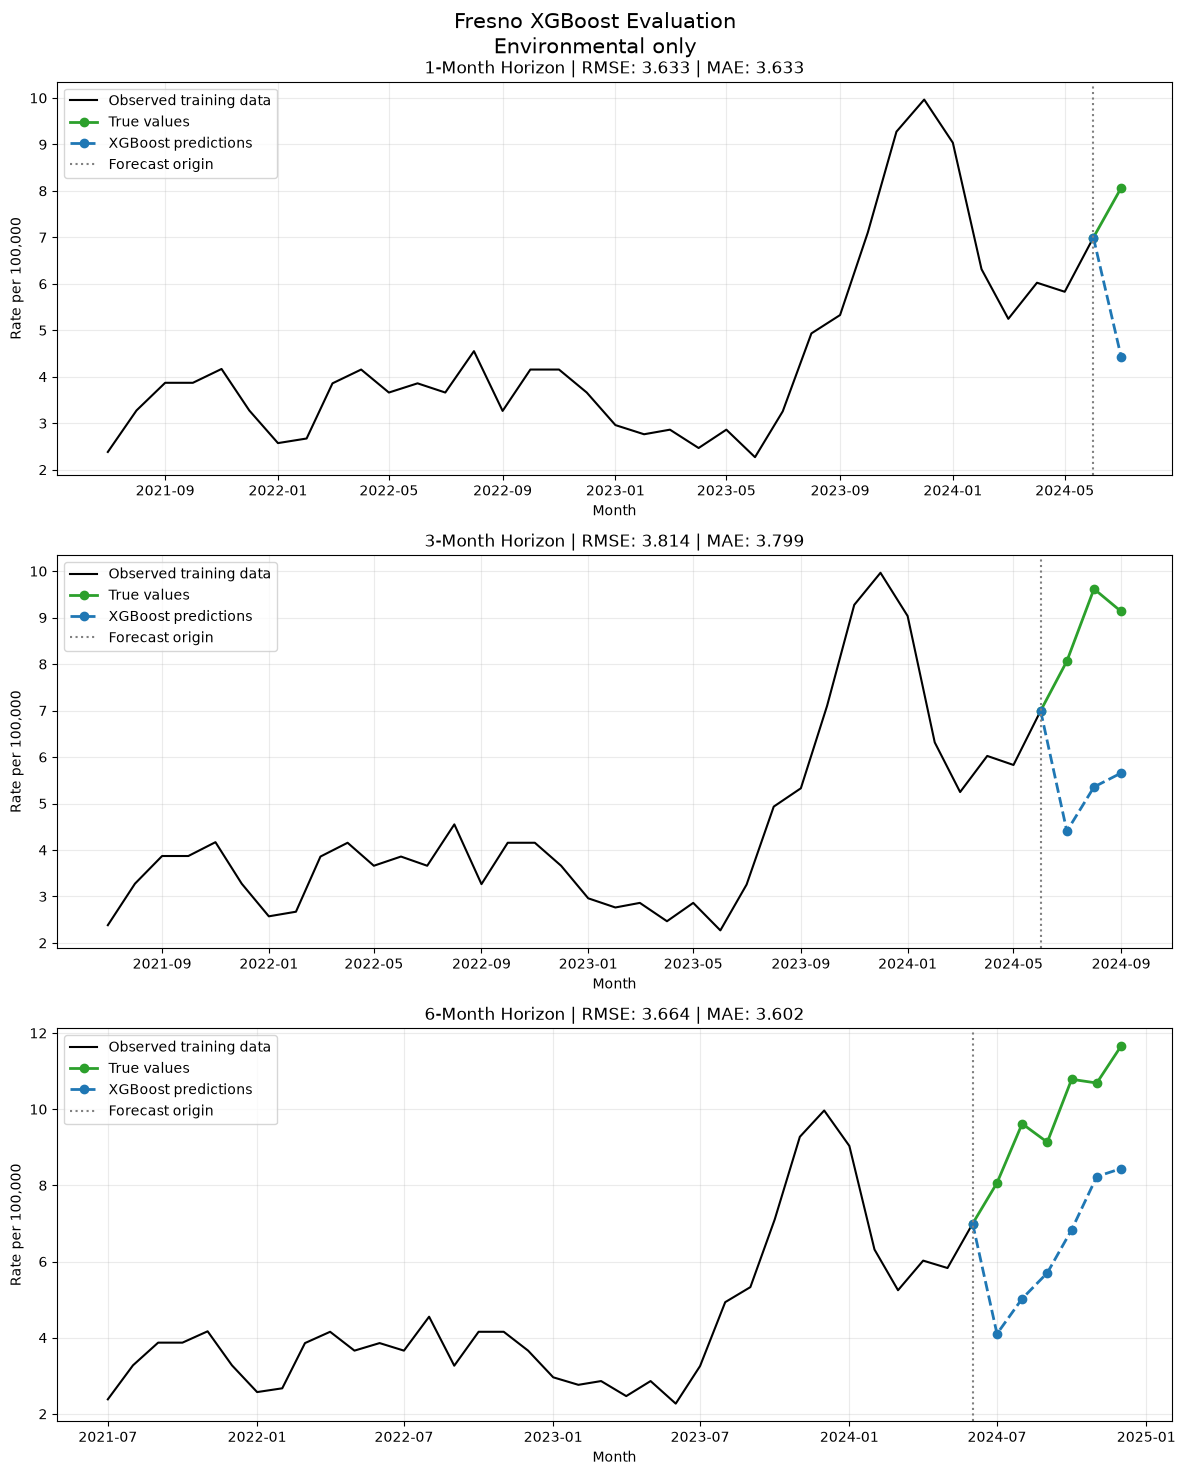

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Lead_Month,Target_Date,Prediction,Actual,Error
0,Fresno,Environmental only,2024-06-01,1,1,2024-07-01,4.430835,8.063874,-3.633039
1,Fresno,Environmental only,2024-06-01,3,1,2024-07-01,4.404698,8.063874,-3.659175
2,Fresno,Environmental only,2024-06-01,3,2,2024-08-01,5.355871,9.618355,-4.262485
3,Fresno,Environmental only,2024-06-01,3,3,2024-09-01,5.656153,9.132580,-3.476427
4,Fresno,Environmental only,2024-06-01,6,1,2024-07-01,4.101835,8.063874,-3.962038
5,Fresno,Environmental only,2024-06-01,6,2,2024-08-01,5.025365,9.618355,-4.592990
6,Fresno,Environmental only,2024-06-01,6,3,2024-09-01,5.701108,9.132580,-3.431472
7,Fresno,Environmental only,2024-06-01,6,4,2024-10-01,6.833242,10.784217,-3.950974
8,Fresno,Environmental only,2024-06-01,6,5,2024-11-01,8.231337,10.687061,-2.455725
9,Fresno,Environmental only,2024-06-01,6,6,2024-12-01,8.440021,11.658613,-3.218592


,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Observations,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Rate_Lags,Environmental_Lags
0,Fresno,Environmental only,2024-06-01,1,1,203,134,3.633039,3.633039,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
1,Fresno,Environmental only,2024-06-01,3,3,201,134,3.814179,3.799362,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
2,Fresno,Environmental only,2024-06-01,6,6,198,134,3.664433,3.601965,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"


In [ ]:
fresno_results = run_xgboost_county(
    county="Fresno",
    evaluation_date=evaluation_date,
    data=data,
    feature_columns=feature_columns,
    horizons=horizons,
    feature_config={
        "use_rate_features": False,
        "rate_lags": tuple(range(12)),
        "environmental_lags": tuple(range(12)),
        "use_log_target": True,
        "include_calendar_features": True},
    model_parameters=xgboost_parameters,
    output_dir=output_dir,
    show_plot=True,
)

display(fresno_results["predictions"])

display(fresno_results["metrics"])

### Feature Importance

In [19]:
fresno_importance = (
    fresno_results["feature_importance"]
    .loc[
        lambda frame:
            (
                frame["Forecast_Horizon"]
                == 6
            )
            & (
                frame["Lead_Month"]
                == 6
            )
    ]
    .sort_values(
        "Importance",
        ascending=False,
    )
)

display(
    fresno_importance.head(20)
)

,County,Model_Version,Forecast_Horizon,Lead_Month,Feature,Importance
1210,Fresno,Environmental only,6,6,Precipitation_lag_4,0.067376
1273,Fresno,Environmental only,6,6,Avg Soil Temp (F)_lag_7,0.032266
1209,Fresno,Environmental only,6,6,Precipitation_lag_3,0.031633
1279,Fresno,Environmental only,6,6,AQI_PM25_lag_1,0.028820
1305,Fresno,Environmental only,6,6,FIRE_Acres_Burned_lag_3,0.028745
1289,Fresno,Environmental only,6,6,AQI_PM25_lag_11,0.027796
1233,Fresno,Environmental only,6,6,Avg Wind Speed (mph)_lag_3,0.026297
1214,Fresno,Environmental only,6,6,Precipitation_lag_8,0.019977
1211,Fresno,Environmental only,6,6,Precipitation_lag_5,0.018922
1285,Fresno,Environmental only,6,6,AQI_PM25_lag_7,0.018569


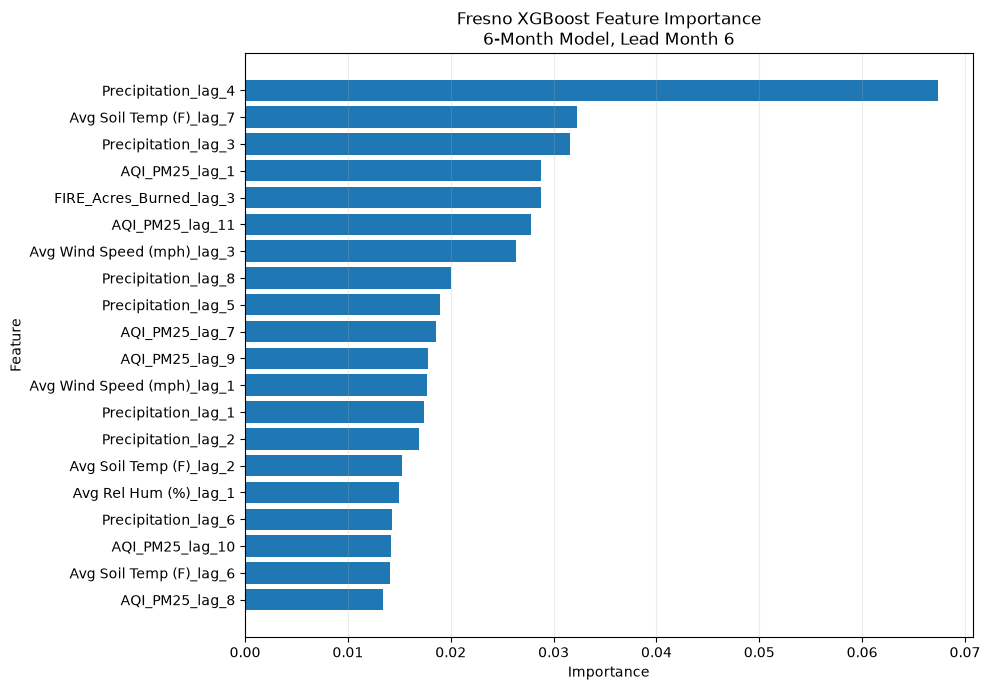

In [20]:
importance_to_plot = (
    fresno_importance
    .head(20)
    .sort_values("Importance")
)

plt.figure(figsize=(10, 7))

plt.barh(
    importance_to_plot["Feature"],
    importance_to_plot["Importance"],
)

plt.title(
    "Fresno XGBoost Feature Importance\n"
    "6-Month Model, Lead Month 6"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.25)
plt.tight_layout()
plt.show()

In [21]:
def run_xgboost_all_counties(
    counties,
    evaluation_date,
    data,
    feature_columns,
    horizons,
    feature_config,
    model_parameters,
    output_dir,
    show_plots=True,
):
    """
    Run the complete XGBoost workflow for every county.
    """

    output_dir = Path(output_dir)

    output_dir.mkdir(
        parents=True,
        exist_ok=True,
    )

    if feature_config["use_rate_features"]:
        model_slug = "with_rate"
    else:
        model_slug = "environment_only"

    county_results = {}
    prediction_results = []
    metric_results = []
    importance_results = []

    for county in counties:
        print(f"Running {county}...")

        results = run_xgboost_county(
            county=county,
            evaluation_date=evaluation_date,
            data=data,
            feature_columns=feature_columns,
            horizons=horizons,
            feature_config=feature_config,
            model_parameters=model_parameters,
            output_dir=output_dir,
            show_plot=show_plots,
        )

        county_results[county] = results

        prediction_results.append(
            results["predictions"]
        )

        metric_results.append(
            results["metrics"]
        )

        importance_results.append(
            results["feature_importance"]
        )

    all_predictions = pd.concat(
        prediction_results,
        ignore_index=True,
    )

    all_metrics = pd.concat(
        metric_results,
        ignore_index=True,
    )

    all_importance = pd.concat(
        importance_results,
        ignore_index=True,
    )

    metric_summary = all_metrics.pivot(
        index="County",
        columns="Forecast_Horizon",
        values=["RMSE", "MAE"],
    )

    date_slug = pd.Timestamp(
        evaluation_date
    ).strftime("%Y-%m")

    all_predictions.to_csv(
        output_dir
        / (
            f"all_counties_xgboost_"
            f"{model_slug}_predictions_"
            f"{date_slug}.csv"
        ),
        index=False,
        date_format="%Y-%m-%d",
    )

    all_metrics.to_csv(
        output_dir
        / (
            f"all_counties_xgboost_"
            f"{model_slug}_metrics_"
            f"{date_slug}.csv"
        ),
        index=False,
        date_format="%Y-%m-%d",
    )

    all_importance.to_csv(
        output_dir
        / (
            f"all_counties_xgboost_"
            f"{model_slug}_importance_"
            f"{date_slug}.csv"
        ),
        index=False,
    )

    metric_summary.to_csv(
        output_dir
        / (
            f"xgboost_{model_slug}_"
            f"metric_summary_"
            f"{date_slug}.csv"
        )
    )

    return {
        "county_results": county_results,
        "predictions": all_predictions,
        "metrics": all_metrics,
        "feature_importance": all_importance,
        "metric_summary": metric_summary,
    }

Running Fresno...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

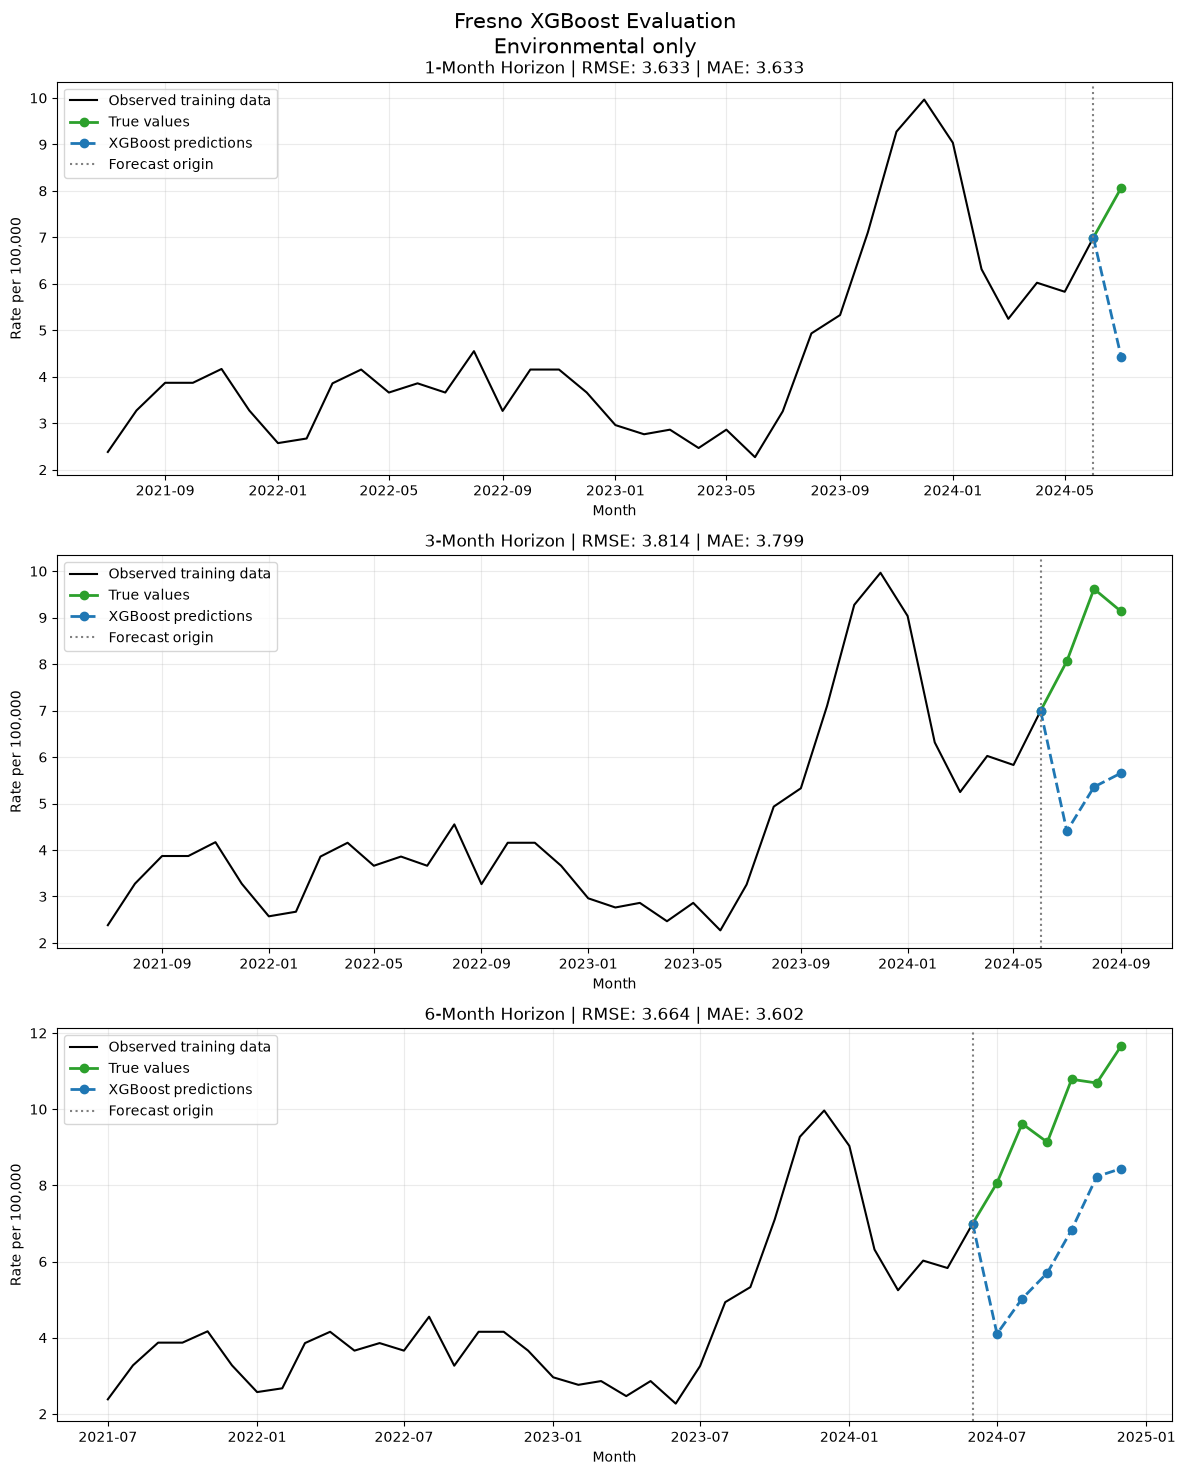

Running Kern...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

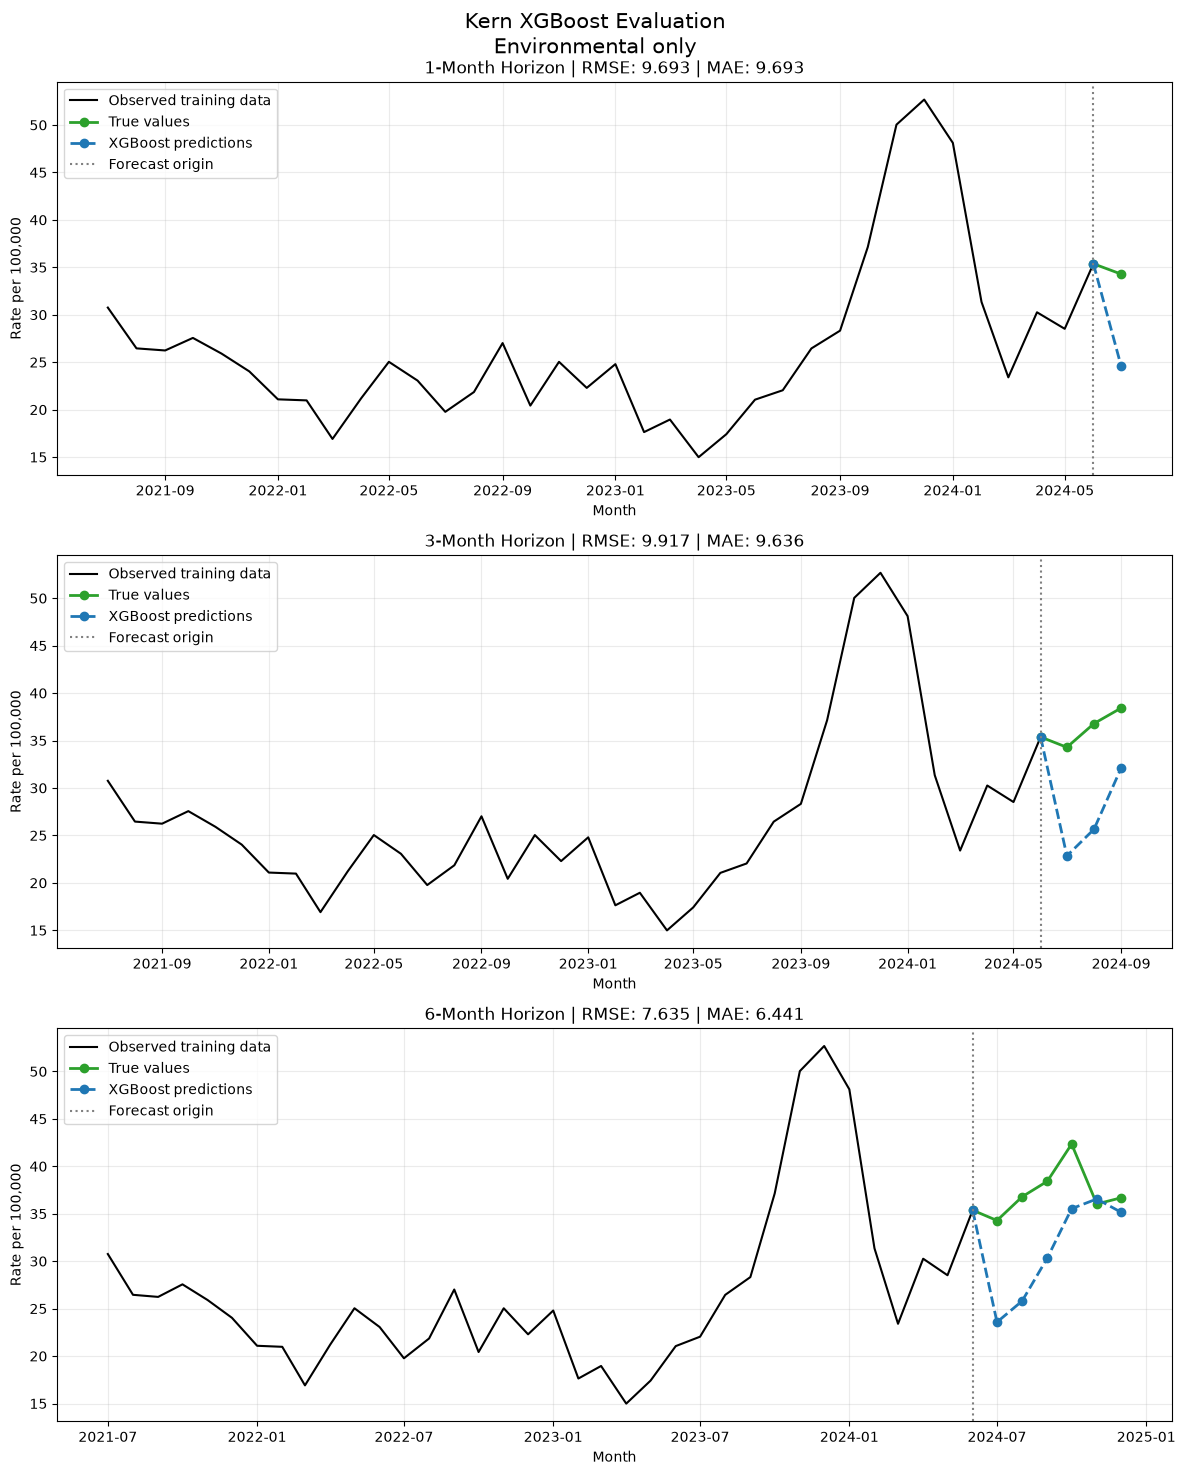

Running Los Angeles...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

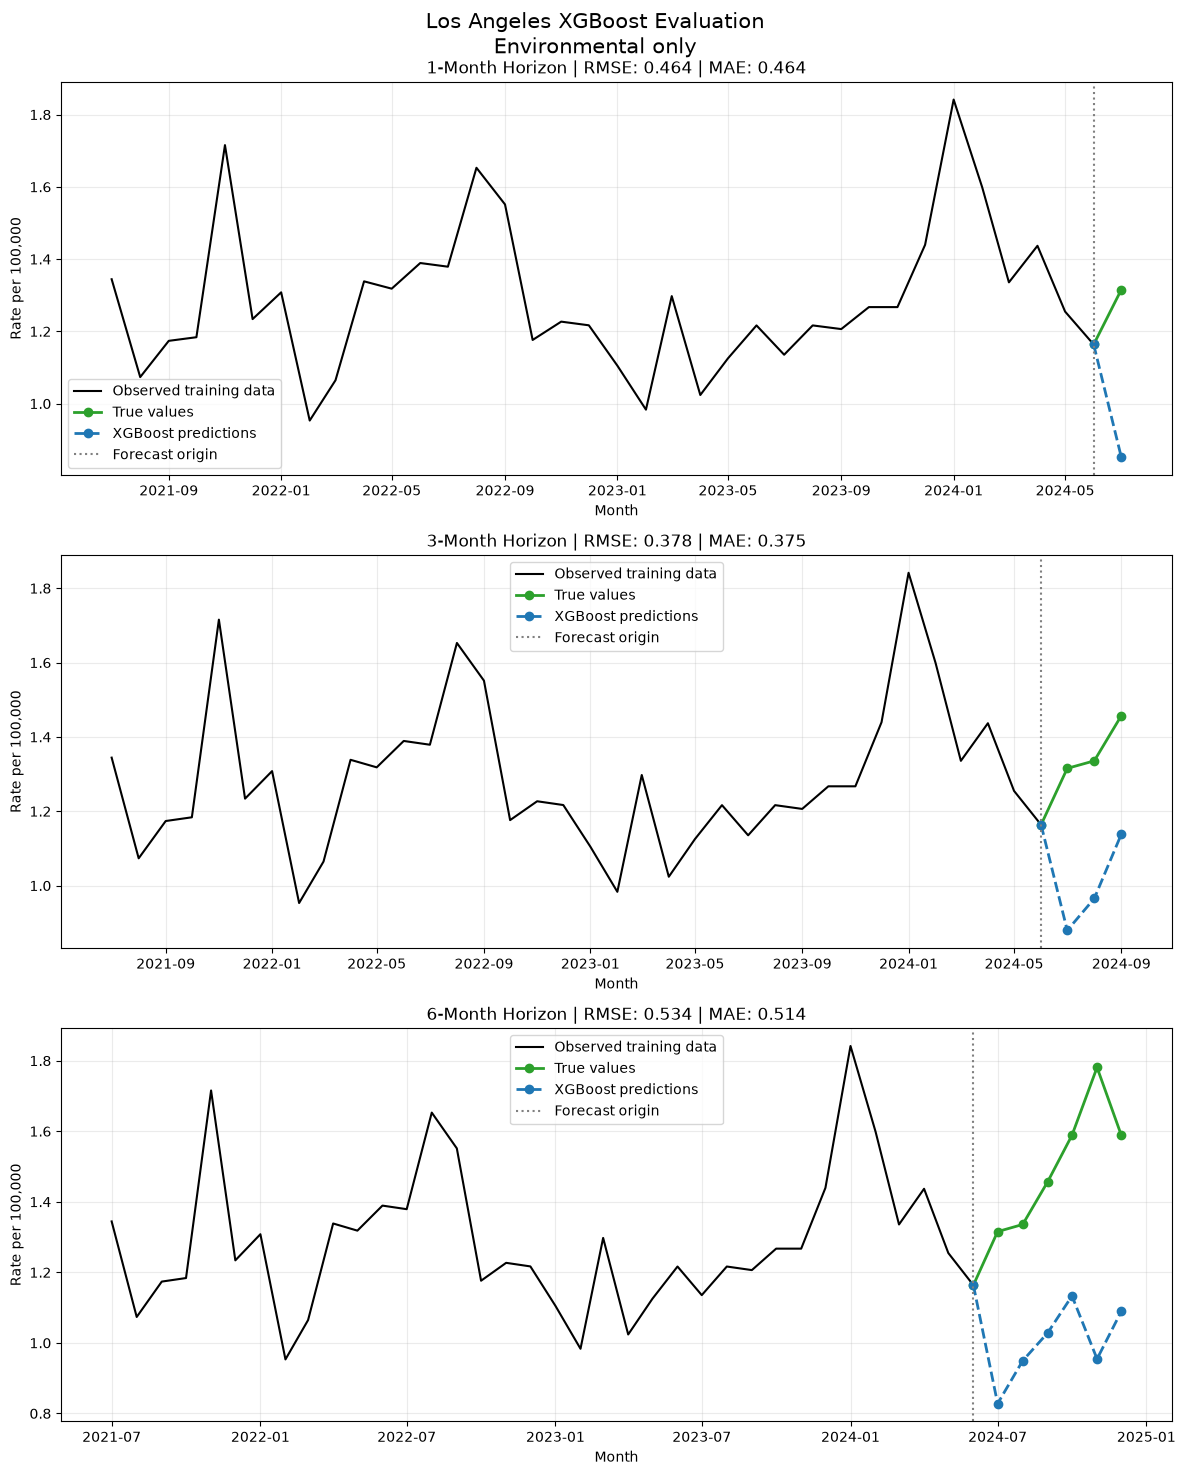

Running Orange...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

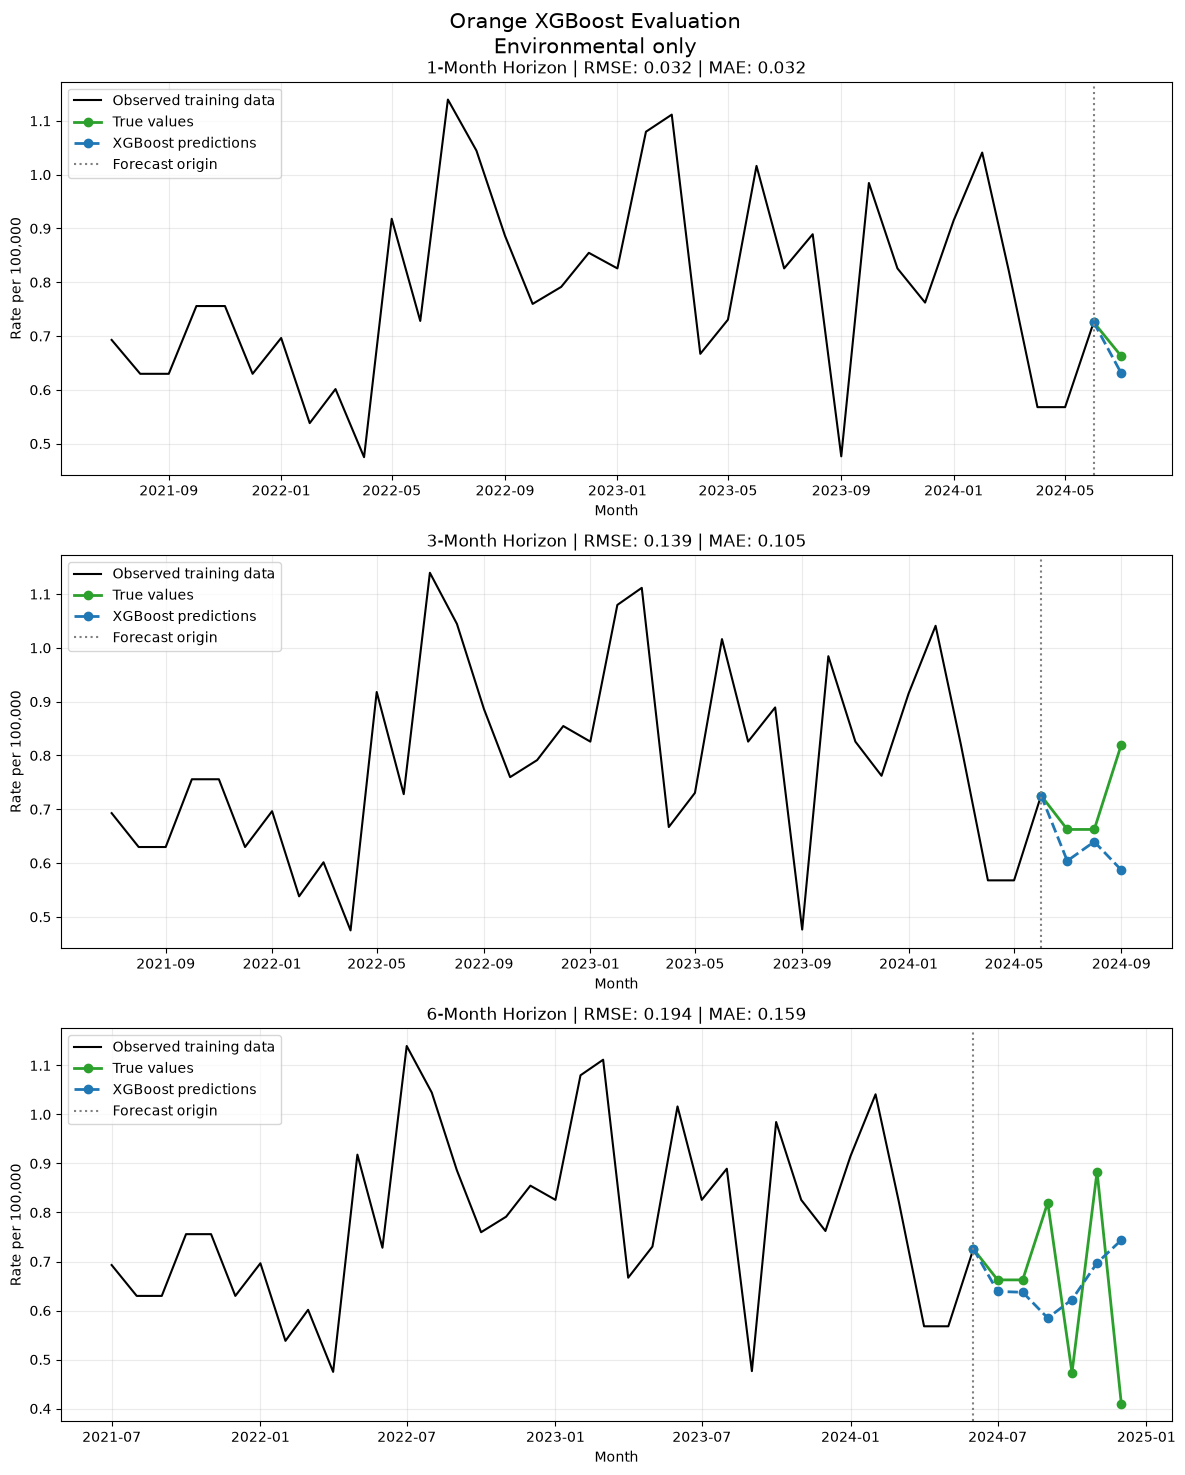

Running San Diego...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

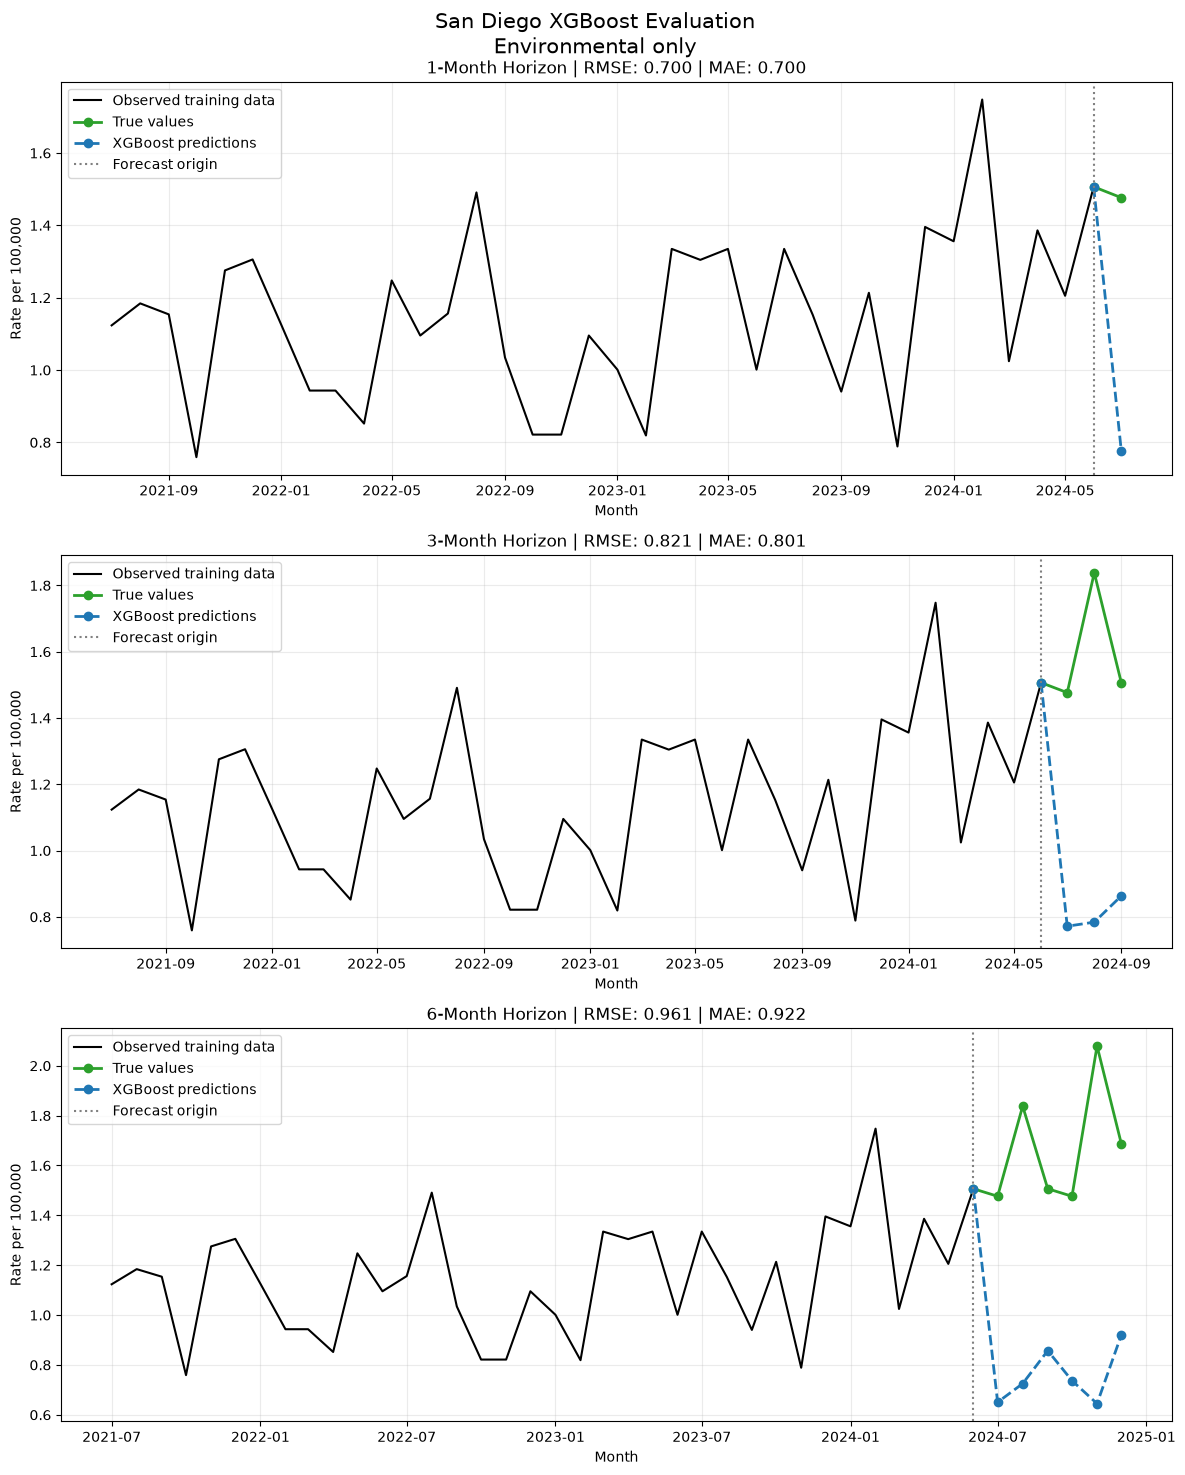

Running San Luis Obispo...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

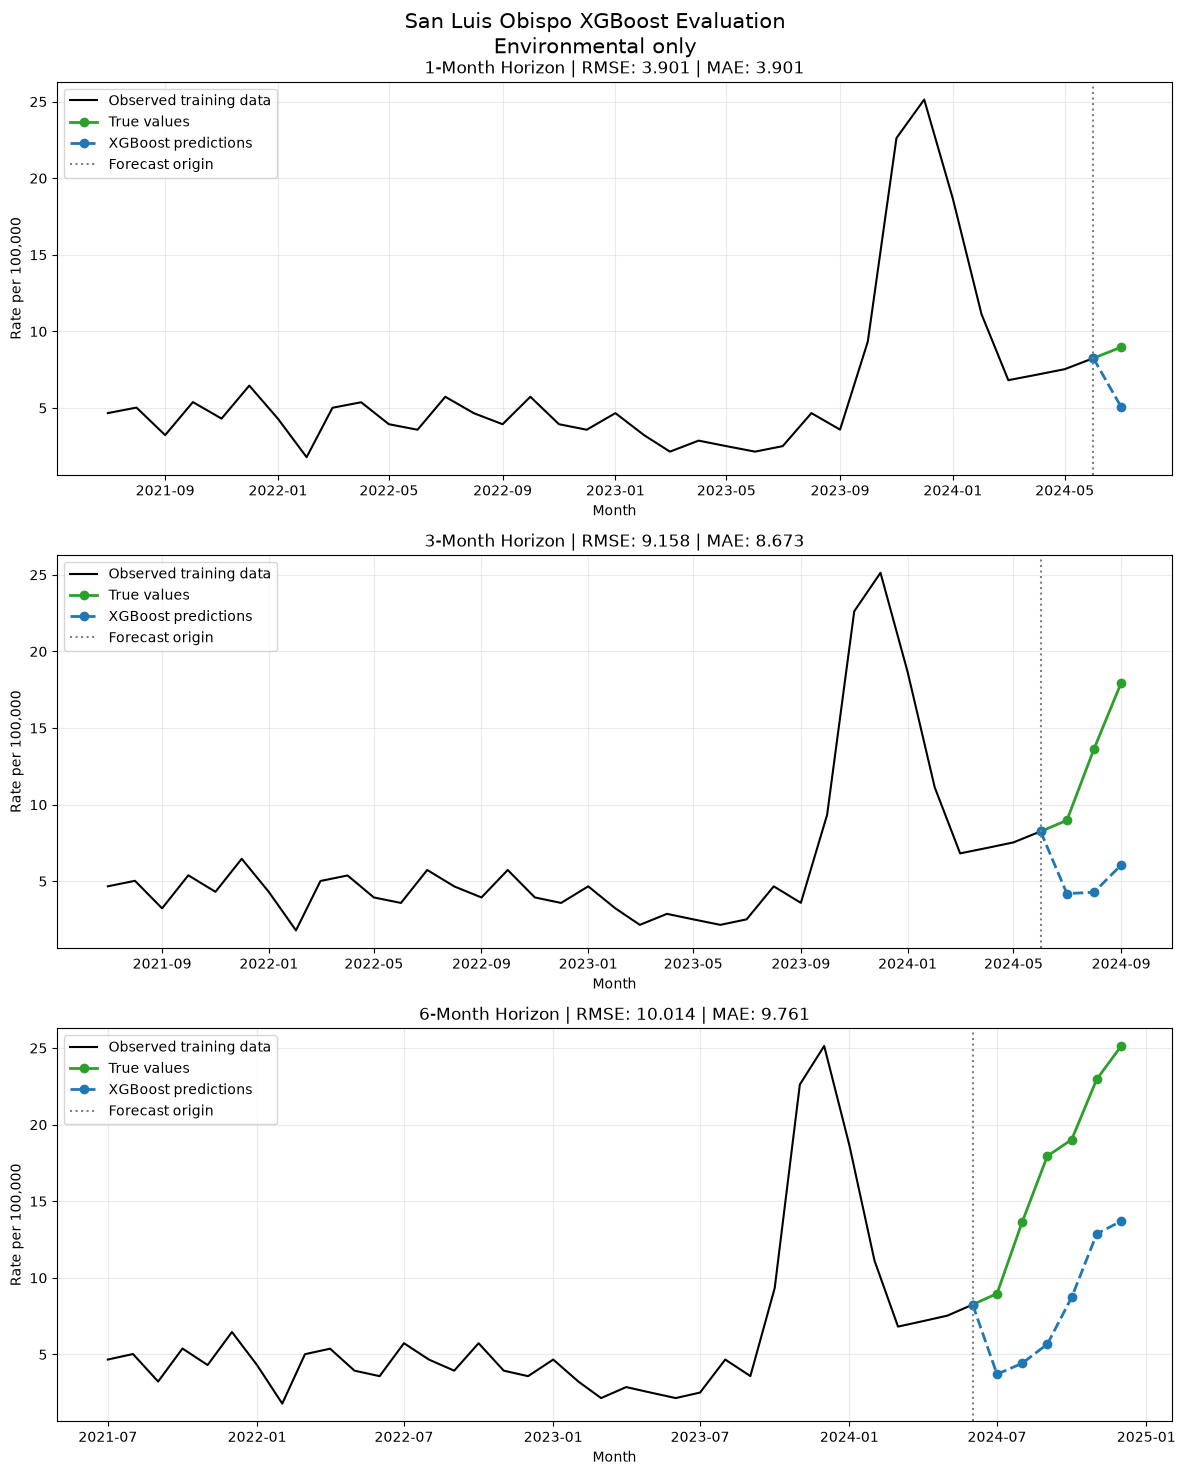

Running Tulare...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

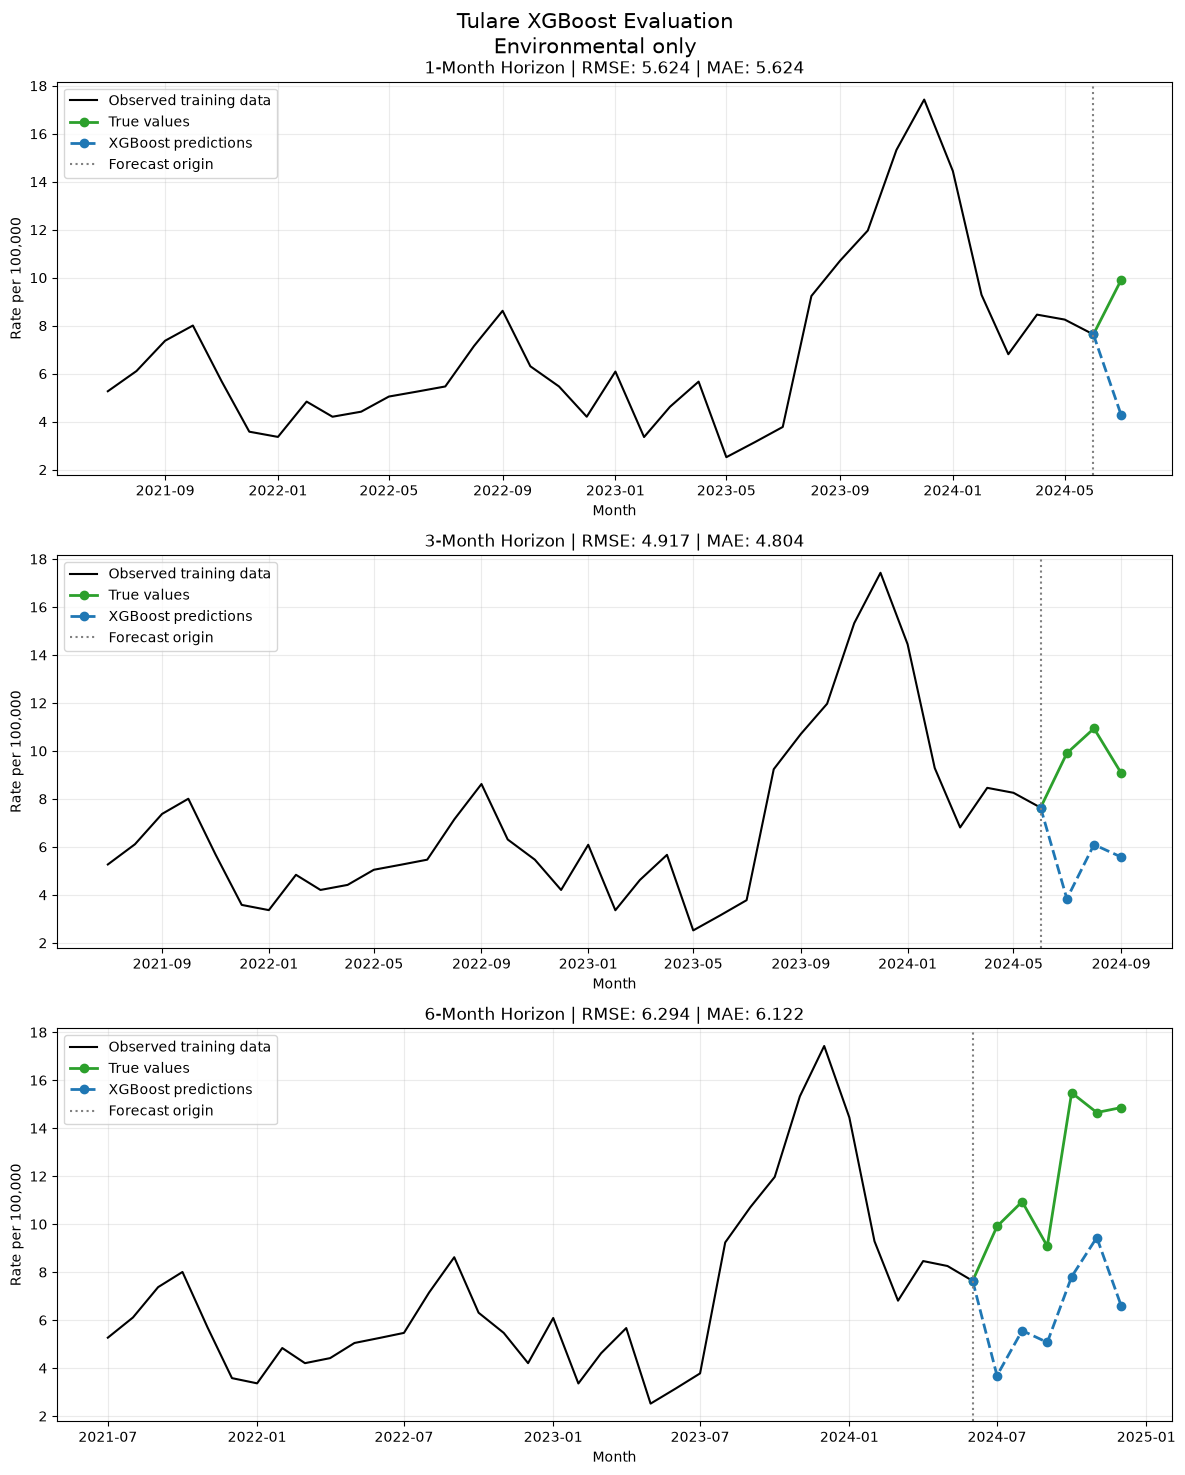

Running Ventura...


C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:19: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data[f"{feature}_lag_{lag}"] = (county_data[feature].shift(lag))
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:24: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  feature_data["month_sin"] = np.sin(2 * np.pi * month / 12)
C:\Users\austi\AppData\Local\Temp\ipykernel_17304\223358553.py:26: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` man

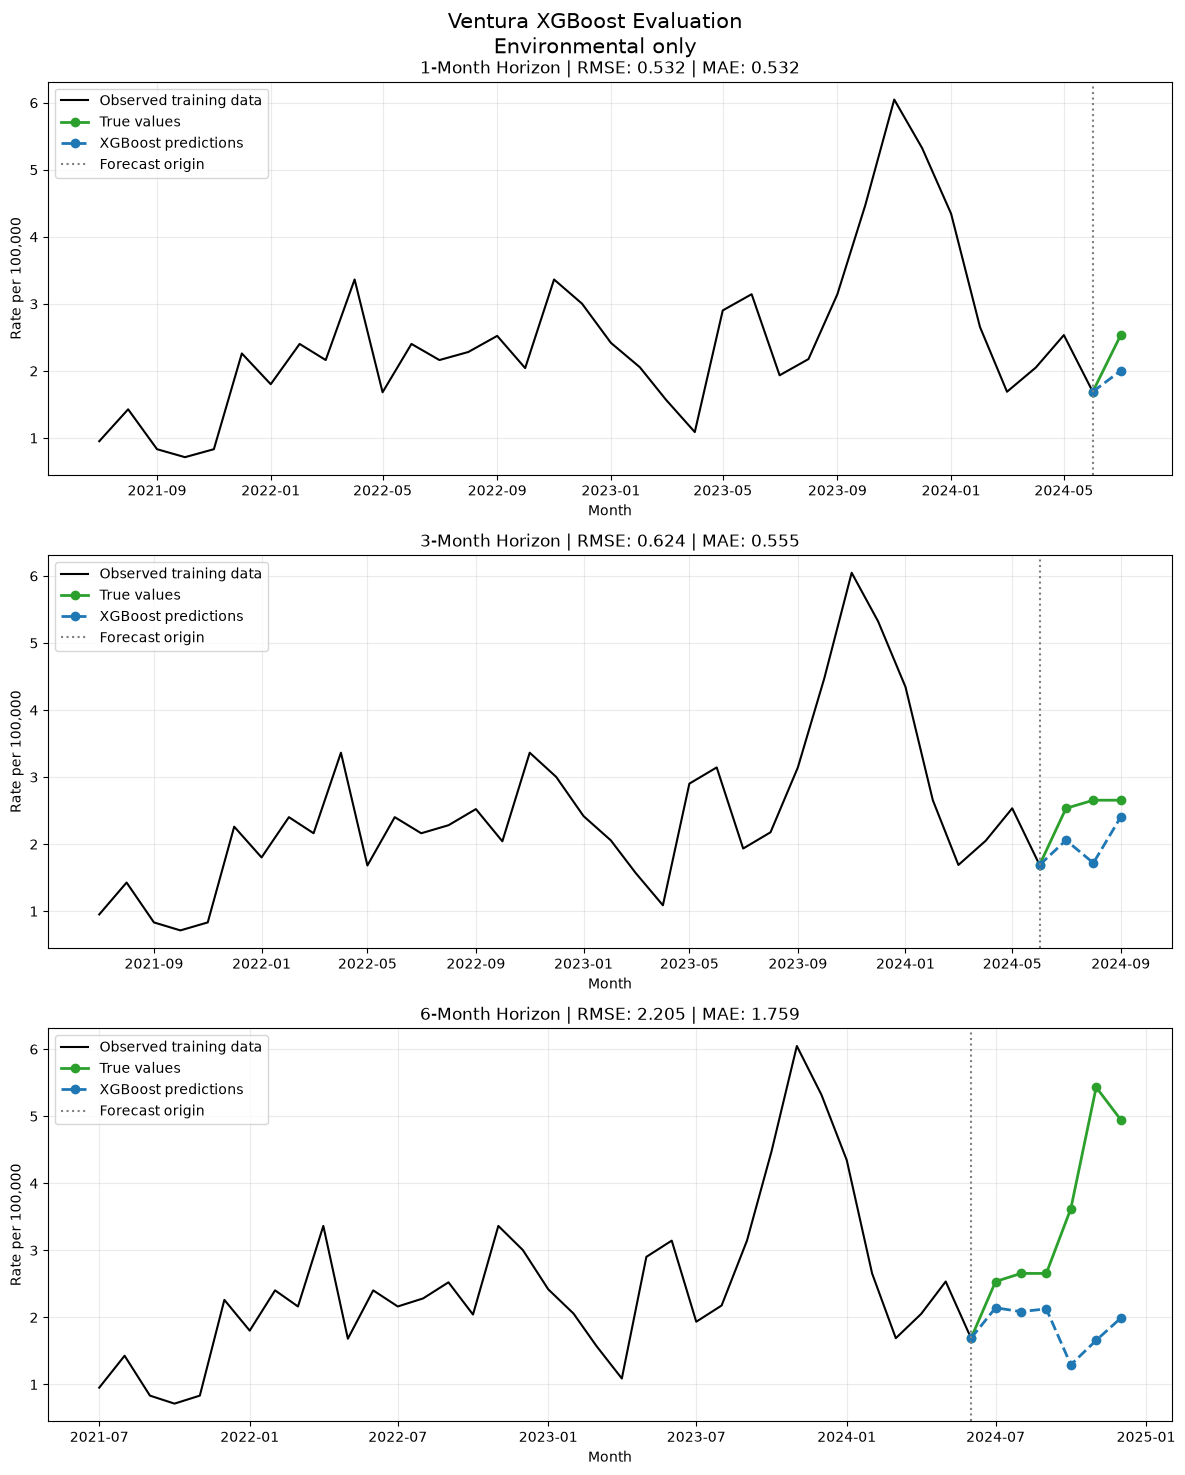

,County,Model_Version,Forecast_Origin,Forecast_Horizon,Evaluation_Months,Training_Observations,Number_Features,RMSE,MAE,Uses_Rate_Features,Uses_Log_Target,Rate_Lags,Environmental_Lags
0,Fresno,Environmental only,2024-06-01,1,1,203,134,3.633039,3.633039,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
1,Fresno,Environmental only,2024-06-01,3,3,201,134,3.814179,3.799362,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
2,Fresno,Environmental only,2024-06-01,6,6,198,134,3.664433,3.601965,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
3,Kern,Environmental only,2024-06-01,1,1,203,134,9.692724,9.692724,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
4,Kern,Environmental only,2024-06-01,3,3,201,134,9.917260,9.636378,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
5,Kern,Environmental only,2024-06-01,6,6,198,134,7.634842,6.440850,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
6,Los Angeles,Environmental only,2024-06-01,1,1,203,134,0.463704,0.463704,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
7,Los Angeles,Environmental only,2024-06-01,3,3,201,134,0.378093,0.375046,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
8,Los Angeles,Environmental only,2024-06-01,6,6,198,134,0.533926,0.513956,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"
9,Orange,Environmental only,2024-06-01,1,1,203,134,0.031818,0.031818,False,True,"(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)","(0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11)"


RMSE                            MAE                    
Forecast_Horizon         1         3          6         1         3         6
County                                                                       
Fresno            3.633039  3.814179   3.664433  3.633039  3.799362  3.601965
Kern              9.692724  9.917260   7.634842  9.692724  9.636378  6.440850
Los Angeles       0.463704  0.378093   0.533926  0.463704  0.375046  0.513956
Orange            0.031818  0.139397   0.193620  0.031818  0.104776  0.158897
San Diego         0.700170  0.820901   0.960526  0.700170  0.800733  0.921602
San Luis Obispo   3.901467  9.158425  10.013693  3.901467  8.672914  9.760604
Tulare            5.623562  4.917435   6.294262  5.623562  4.804317  6.122474
Ventura           0.531987  0.623718   2.205396  0.531987  0.554597  1.758714

In [22]:
all_xgboost_environment_only = (
    run_xgboost_all_counties(
        counties=counties,
        evaluation_date=evaluation_date,
        data=data,
        feature_columns=feature_columns,
        horizons=horizons,
        feature_config={
            "use_rate_features": False,
            "rate_lags": tuple(range(12)),
            "environmental_lags": tuple(range(12)),
            "use_log_target": True,
            "include_calendar_features": True},
        model_parameters=xgboost_parameters,
        output_dir=output_dir,
        show_plots=True,
    )
)

display(all_xgboost_environment_only["metrics"])

display(all_xgboost_environment_only["metric_summary"])